## Notebook setup

In [10]:
import os, sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = os.environ.get("BASE", "/content/drive/MyDrive/Colab Notebooks/Pik1-DE-FT")
    %pip install -q -r https://raw.githubusercontent.com/<user>/<repo>/main/requirements.txt
else:
    BASE_DIR = os.environ.get("BASE", os.path.abspath(".."))  # repo root if run from notebooks/

DATA_DIR = f"{BASE_DIR}/YSD_Analysis/Output"
OUT_DIR = f"{BASE_DIR}/Outputs"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/bin/bash: line 1: user: No such file or directory


In [11]:
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [12]:
cm = 1 / 2.54
GENOTYPE_ORDER = ["Pikh-1", "VK", "SHZ-2"]
LIGAND_ORDER = ["Avr-PikA", "Avr-PikC"]
REFERENCE = "Pikh-1"
SESSION_MARKERS = ["o", "s", "^", "D", "v"]
SESSION_PALETTE = "colorblind"
RANGE_COLOR = "0.6"
MEDIAN_COLOR = "black"
GENOTYPE_COLORS = {
    "Pikh-1": "#CC79A7",   # pink
    "VK":     "#0072B2",   # blue
    "SHZ-2":  "#009E73",   # green
}
FONT_PREFERENCE = ["Arial", "Liberation Sans", "Helvetica", "Nimbus Sans", "DejaVu Sans"]
SAVE_FORMATS = ["svg", "png"]
DPI = 300

In [13]:
def resolve_font(preference=FONT_PREFERENCE):
  import matplotlib.font_manager as fm
  available = {f.name for f in fm.fontManager.ttflist}
  for name in preference:
      if name in available:
          return name
  return "DejaVu Sans"

def apply_style():
  font = resolve_font()
  sns.set_theme(style="ticks")
  mpl.rcParams.update({
      "font.family": "sans-serif",
      "font.sans-serif": [font] + FONT_PREFERENCE,
      "font.size": 8,
      "axes.titlesize": 8,
      "axes.labelsize": 8,
      "xtick.labelsize": 8,
      "ytick.labelsize": 8,
      "legend.fontsize": 7,
      "legend.title_fontsize": 8,
      "axes.linewidth": 1.5,
      "xtick.major.width": 1.5,
      "ytick.major.width": 1.5,
      "xtick.major.size": 5,
      "ytick.major.size": 5,
      "axes.spines.top": False,
      "axes.spines.right": False,
      "legend.frameon": False,
      "savefig.bbox": "tight",
      "savefig.transparent": False,
      "pdf.fonttype": 42,
      "ps.fonttype": 42,
  })

def save(fig, stem):
  for ext in SAVE_FORMATS:
      fig.savefig(f"{OUT_DIR}/figures/{stem}.{ext}", dpi=DPI)
  print(f"wrote {stem}.{'/'.join(SAVE_FORMATS)}")


def ordered(df, col, order):
  present = [x for x in order if x in set(df[col])]
  missing = sorted(set(df[col]) - set(order))
  if missing:
      print(f"  note: unexpected {col} values ignored: {missing}")
  out = df[df[col].isin(present)].copy()
  out[col] = pd.Categorical(out[col], present, ordered=True)
  return out, present

apply_style()

## YSD microscopy figure

In [14]:
def plot_ysd(q_path, s_path, stem="ysd_normalized_binding"):
    q_df = pd.read_csv(q_path)
    s_df = pd.read_csv(s_path)

    q_df, _ = ordered(q_df, "genotype", GENOTYPE_ORDER)
    s_df, _ = ordered(s_df, "genotype", GENOTYPE_ORDER)
    q_df, ligands = ordered(q_df, "ligand", LIGAND_ORDER)
    s_df, _ = ordered(s_df, "ligand", LIGAND_ORDER)

    genos = [g for g in GENOTYPE_ORDER if g in set(q_df["genotype"])]
    xpos = {g: i for i, g in enumerate(genos)}

    _fb = sns.color_palette(SESSION_PALETTE, len(genos))
    gpal = {g: GENOTYPE_COLORS.get(g, _fb[i]) for i, g in enumerate(genos)}

    sessions = sorted(s_df["session"].astype(str).unique())
    pal = dict(zip(sessions, sns.color_palette(SESSION_PALETTE, len(sessions))))
    mrk = dict(zip(sessions, SESSION_MARKERS * (len(sessions) // 5 + 1)))

    fig, axes = plt.subplots(1, len(ligands), figsize=(18*cm, 5.5*cm),
                             sharey=True)
    axes = np.atleast_1d(axes)

    for ax, lig in zip(axes, ligands):
        q = q_df[q_df["ligand"] == lig]
        s = s_df[s_df["ligand"] == lig]

        ax.axhline(0, ls=(0, (4, 3)), lw=0.5, color="black", zorder=0)

        for _, row in q.iterrows():
          x = xpos[row["genotype"]]
          col = gpal[row["genotype"]]
          ax.vlines(x, row["min"], row["max"], lw=0.5, color=col, alpha=0.45, zorder=1)
          ax.vlines(x, row["q10"], row["q90"], lw=3, color=col, alpha=0.70, zorder=2)
          ax.vlines(x, row["q25"], row["q75"], lw=6, color=col, zorder=3)
          ax.hlines(row["med"], x - 0.075, x + 0.075, lw=1.2, color=MEDIAN_COLOR, zorder=4)

        for sess in sessions:
            sub = s[s["session"].astype(str) == sess]
            if sub.empty:
                continue
            ax.scatter([xpos[g] + 0.30 for g in sub["genotype"]], sub["rel"],
                       marker=mrk[sess], s=25, color=pal[sess],
                       edgecolor="white", linewidth=0.4, zorder=4)

        ax.set_title(lig)
        ax.set_xticks(range(len(genos)))
        ax.set_xticklabels(genos)
        ax.set_xlim(-0.55, len(genos) - 0.25)
        ax.set_xlabel("")

    axes[0].set_ylabel(r"Log$_2$(ligand / receptor) signal")
    handles = [plt.Line2D([], [], marker=mrk[s], color=pal[s], ls="none",
                          markersize=5, markeredgecolor="white",
                          markeredgewidth=0.4, label=s)
               for s in sessions]
    axes[-1].legend(handles=handles, title="Session",
                    loc="upper left", bbox_to_anchor=(1.02, 1.0))

    sns.despine(fig=fig)
    fig.tight_layout()
    save(fig, stem)
    return fig

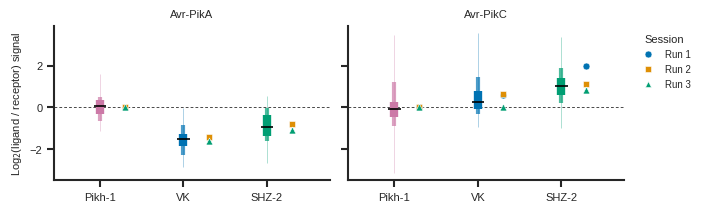

In [15]:
fig_ysd = plot_ysd(f"{DATA_DIR}/YSD/ysd_quantiles.csv",
                   f"{DATA_DIR}/YSD/ysd_session_means.csv")

## FACS densities figure

In [16]:
def plot_facs(path, stem="facs_normalized_binding", xlim=(-5, 5)):
    df = pd.read_csv(path).rename(columns={"ligand_id": "ligand"})

    df, _ = ordered(df, "genotype", GENOTYPE_ORDER)
    df, ligands = ordered(df, "ligand", LIGAND_ORDER)

    genos = [g for g in GENOTYPE_ORDER if g in set(df["genotype"])]
    _fallback = sns.color_palette(SESSION_PALETTE, len(genos))
    pal = {g: GENOTYPE_COLORS.get(g, _fallback[i]) for i, g in enumerate(genos)}
    fig, axes = plt.subplots(1, len(ligands),
                             figsize=(18*cm, 4.5*cm),
                             sharey=True, sharex=True)
    axes = np.atleast_1d(axes)

    for ax, lig in zip(axes, ligands):
        sub = df[df["ligand"] == lig]
        for g in genos:
            vals = sub.loc[sub["genotype"] == g, "norm"].dropna()
            if vals.empty:
                continue
            sns.kdeplot(x=vals, ax=ax, color=pal[g], lw=1.1, fill=True, alpha=0.35,
                        common_norm=False, cut=0)
        ax.set_title(lig)
        ax.set_xlim(*xlim)
        ax.set_xlabel(r"Log$_2$(ligand / receptor) signal")
        ax.set_ylabel("")

    axes[0].set_ylabel("Density")

    handles = [plt.Line2D([], [], color=pal[g], lw=1.1, label=g) for g in genos]
    axes[-1].legend(handles=handles, title="Receptor Allele",
                    loc="upper left", bbox_to_anchor=(1.02, 1.0))

    sns.despine(fig=fig)
    fig.tight_layout()
    #save(fig, stem)
    return fig

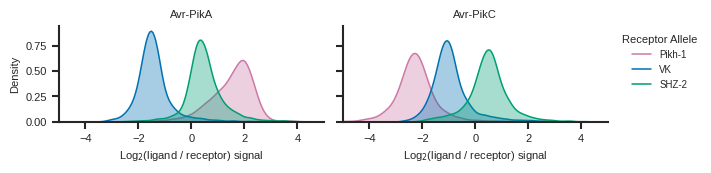

In [17]:
fig_facs = plot_facs(f"{DATA_DIR}/FACS/facs_normalized_cells.csv")